# Synthetic-trained bounded median correction of sMOA

This smoke demonstration forecasts a hypothetical unseen disease from six observations and the unchanged full reference. Only independent synthetic training/validation outcomes enter fitting and selection. One absolute-error regressor learns a normalized correction bounded by the available analogue/original envelope. The unchanged acceptance gates can retain original sMOA at rho=0. The old rank classifier remains an experimental comparator; COVID outcomes never train, tune or calibrate the correction.

In [1]:
from pathlib import Path
import sys, json, joblib
ROOT=Path.cwd()
if not (ROOT/'configs/experiments.json').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from experiments.robust.pipeline import load_config,run
from threadpoolctl import threadpool_limits
limits=threadpool_limits(1)
from experiments.robust.correction_experiment import WeightedForecast
from experiments.robust.data import load_reference
from experiments.robust.policy import candidate_features,FEATURES
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
config=load_config(ROOT/'configs/experiments.json')
RUN=run(config,experiment='correction',smoke=True)
policy=joblib.load(RUN/'median_model.joblib')
frozen=json.loads((RUN/'selected_model.json').read_text())
engine,_,_=load_reference(config)
history=np.array([10.,14.,17.,22.,31.,40.])
original=engine.match(history).baseline
final,details=policy.forecast(engine,history,frozen['rho'])
unblended=policy.forecast(engine,history,1.)[0]
print('Hypothetical observations:',history)
print('Selected method:',frozen['selected_method'],'rho:',frozen['rho'])
weighted=WeightedForecast().forecast(engine,history)[0]
display(pd.DataFrame(details['candidates'],columns=['lower cumulative Q25','exact original','upper cumulative Q75'],index=range(1,5)))
display(pd.DataFrame({'normalized correction':details['normalized_correction'],'candidate correction':unblended-original,'selected correction':final-original},index=range(1,5)))

Reusing immutable complete run: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/robust_smoa/median_correction/smoke_f356273d7fb98182


Hypothetical observations: [10. 14. 17. 22. 31. 40.]
Selected method: original_smoa rho: 0.0


,lower cumulative Q25,exact original,upper cumulative Q75
1,43.0,55.0,81.00
2,49.0,75.0,150.00
3,54.0,99.5,254.75
4,60.0,127.5,412.00


,normalized correction,candidate correction,selected correction
1,0.663411,25.209615,0.0
2,0.672212,67.893377,0.0
3,0.705886,141.706648,0.0
4,0.705886,248.471931,0.0


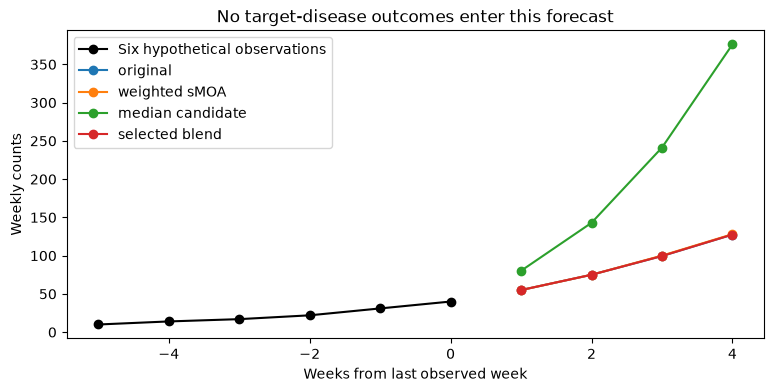

In [2]:
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(range(-5,1),history,'ko-',label='Six hypothetical observations')
for label,value in [('original',original),('weighted sMOA',weighted),('median candidate',unblended),('selected blend',final)]:
    ax.plot(range(1,5),value,'o-',label=label)
ax.set(xlabel='Weeks from last observed week',ylabel='Weekly counts',title='No target-disease outcomes enter this forecast')
ax.legend();plt.show()


TreeSHAP explains the candidate's unbounded normalized residual median, before scaling, envelope clipping and blending. Direct Kernel SHAP explains actual weighted/median candidate forecasts and their differences from original sMOA. These candidates remain experimental at selected rho=0; no zero selected contrast is presented as an improvement. Backgrounds use independent synthetic whole histories rescaled by observed mean only. Correlated weeks, hybrid histories and background dependence limit interpretation. SHAP is not causal evidence.

/Users/nguyentranglinh/infectious-disease-forecasting/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


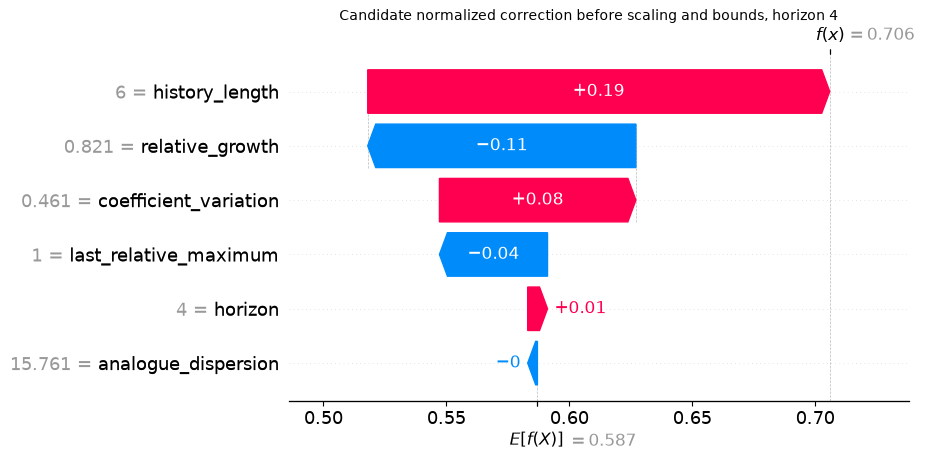

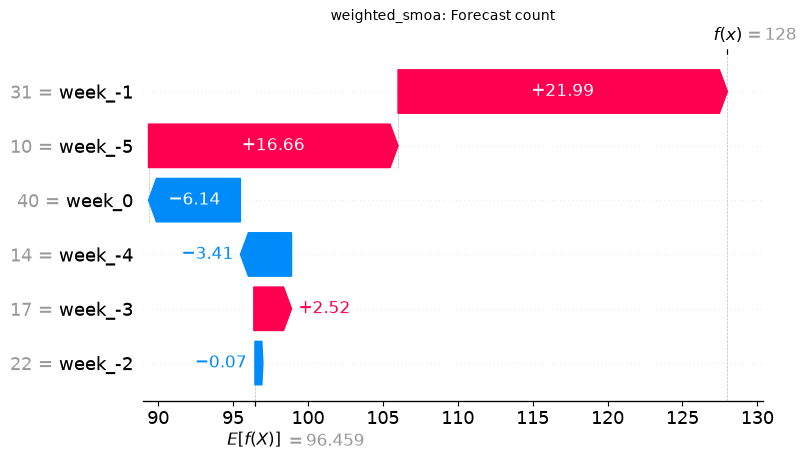

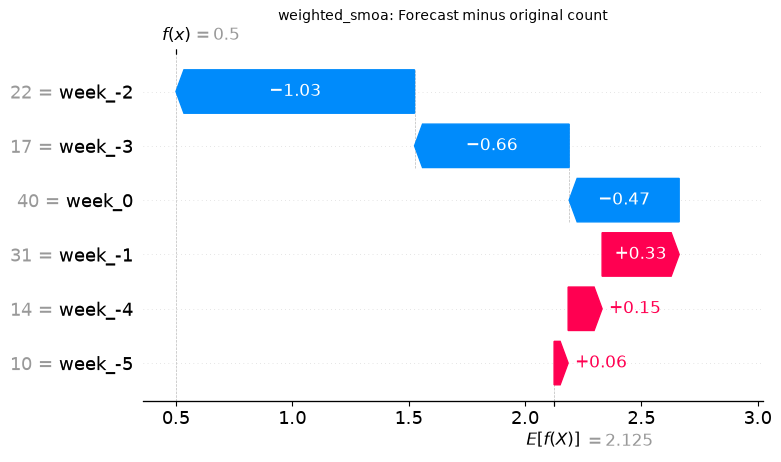

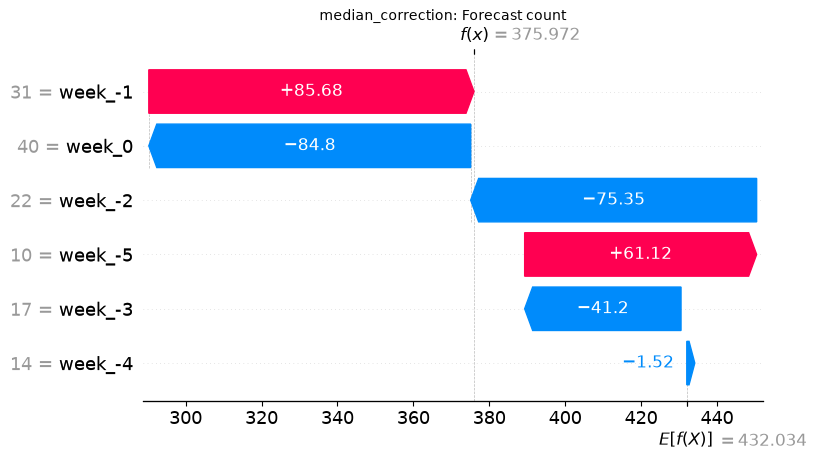

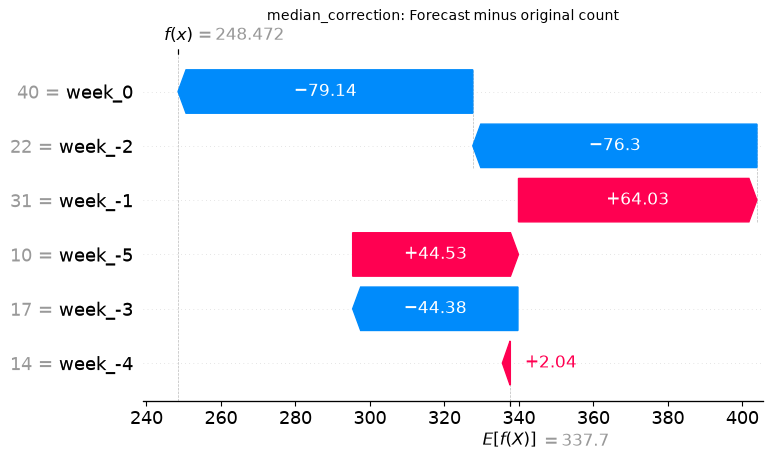

In [3]:
import shap
from experiments.robust.explain import DirectForecast,background_histories,plot_explanation
from bank import load_packed
x=candidate_features(engine,history)[0]
e=shap.TreeExplainer(policy.model)(x)
e.feature_names=FEATURES
np.testing.assert_allclose(e.base_values+e.values.sum(axis=1),policy.model.predict(x),atol=1e-6)
plot_explanation(e[-1],'Candidate normalized correction before scaling and bounds, horizon 4');plt.show()
identity=json.loads((RUN/'run_config.json').read_text())
folder=Path(identity['synthetic_folder'])
meta=json.loads((folder/'metadata.json').read_text())
meta['background']=load_packed(folder/'background.npz')
bg=background_histories(meta,6,history,4,config['seed'])
for name,model in [('weighted_smoa',WeightedForecast()),('median_correction',policy)]:
    wrapper=DirectForecast(engine,dict(temperature=4.,beta=0.),4,policy=model,rho=1.)
    if wrapper(history)[0,1]==0:
        print(name,': no local adjustment to explain');continue
    np.random.seed(config['seed'])
    explainer=shap.KernelExplainer(wrapper,bg)
    phi=np.asarray(explainer.shap_values(history[None,:],nsamples=64,l1_reg=0,silent=True))[0]
    np.testing.assert_allclose(np.asarray(explainer.expected_value)+phi.sum(axis=0),wrapper(history)[0],atol=1e-6)
    for output,label in enumerate(['Forecast count','Forecast minus original count']):
        local=shap.Explanation(values=phi[:,output],base_values=explainer.expected_value[output],data=history,feature_names=[f'week_{i-5}' for i in range(6)])
        plot_explanation(local,name+': '+label);plt.show()

The following smoke metrics are a separate retrospective evaluation, not actuals for the hypothetical sequence. Descriptive names distinguish the three frozen baselines, the unblended median candidate, and the forecast selected using synthetic validation alone. COVID has been examined repeatedly during development and remains exploratory evidence. A fallback to rho=0 is a valid negative result.

In [4]:
display(pd.read_csv(RUN/'metrics.csv')[['dataset','model','n','mae','rmse','bias','nmae']])
display(pd.read_csv(RUN/'validation_selection.csv'))
display(pd.read_csv(RUN/'improved_worsened.csv'))
print('These are labelled smoke results. The full study uses nested 288/576 training curves, 108 fresh validation, 72 check and 36 stress curves.')
print('Frozen initial NB intervals are comparators, not target-calibrated policy uncertainty.')

,dataset,model,n,mae,rmse,bias,nmae
0,COVID19_early,original_smoa,24,357.875000,595.221440,-208.500000,0.978228
1,COVID19_early,weighted_smoa,24,362.625000,602.281876,-217.541667,0.991541
2,COVID19_early,historical_rank_policy,24,360.912202,603.969532,-155.147379,0.949454
3,COVID19_early,median_correction,24,392.620893,621.386447,14.440734,0.924695
4,COVID19_early,selected_forecast,24,357.875000,595.221440,-208.500000,0.978228
5,synthetic_check,original_smoa,108,143891.740741,347680.917448,97213.657407,2.051142
6,synthetic_check,weighted_smoa,108,145105.685185,351666.749752,96721.629630,2.043027
7,synthetic_check,historical_rank_policy,108,155484.287285,361360.240998,107741.877996,2.609136
8,synthetic_check,median_correction,108,220084.744464,568372.901644,189819.565436,3.323535
9,synthetic_check,selected_forecast,108,143891.740741,347680.917448,97213.657407,2.051142


,training_size,training_curves,rho,eligible,rejection_reasons,n,mae,rmse,bias,nmae,severe_underprediction,severe_overprediction
0,small,9,0.00,False,raw_mae;normalized_mae,108,22757.726852,42789.867834,5725.134259,7.857208,0.166667,0.138889
1,small,9,0.25,False,raw_mae;rmse,108,29453.217933,69611.055410,15101.225907,7.750369,0.166667,0.194444
2,small,9,0.50,False,raw_mae;rmse,108,36776.648829,100677.038726,24477.317556,7.692583,0.148148,0.231481
3,small,9,1.00,False,raw_mae;rmse,108,52603.222859,165959.401196,43229.500852,7.581877,0.111111,0.296296
4,large,9,0.00,False,raw_mae;normalized_mae,108,22757.726852,42789.867834,5725.134259,7.857208,0.166667,0.138889
5,large,9,0.25,False,raw_mae;rmse,108,29453.217933,69611.055410,15101.225907,7.750369,0.166667,0.194444
6,large,9,0.50,False,raw_mae;rmse,108,36776.648829,100677.038726,24477.317556,7.692583,0.148148,0.231481
7,large,9,1.00,False,raw_mae;rmse,108,52603.222859,165959.401196,43229.500852,7.581877,0.111111,0.296296


,dataset,model,n,improved,worsened,ties
0,COVID19_early,historical_rank_policy,24,15,9,0
1,COVID19_early,median_correction,24,16,8,0
2,COVID19_early,original_smoa,24,0,0,24
3,COVID19_early,selected_forecast,24,0,0,24
4,COVID19_early,weighted_smoa,24,4,12,8
5,synthetic_check,historical_rank_policy,108,47,57,4
6,synthetic_check,median_correction,108,36,68,4
7,synthetic_check,original_smoa,108,0,0,108
8,synthetic_check,selected_forecast,108,0,0,108
9,synthetic_check,weighted_smoa,108,34,59,15


These are labelled smoke results. The full study uses nested 288/576 training curves, 108 fresh validation, 72 check and 36 stress curves.
Frozen initial NB intervals are comparators, not target-calibrated policy uncertainty.
